# DP1 – Handling missing data by removal of data records

**Dataset:** `dataIsRemovalAllowed` — columns: *gender* (binary coded), *age*, *preference score* (0–10).
**Goal:** estimate the **mean preference** for the product.

**(a)** Can rows with missing data be removed without significantly influencing the result?
**Answer: NO.** The missing values are **not missing completely at random (MCAR)**. The probability that a
record is incomplete depends on who the respondent is (age / gender), and these same groups have a
systematically different preference. Deleting incomplete rows (*listwise deletion / complete-case analysis*)
therefore removes mostly high-preference respondents, so the remaining sample is no longer representative and
the mean preference is **underestimated**.

The notebook shows this graphically in five steps:
1. Where are the missing values? (missingness map)
2. Who is missing? (missingness rate by gender and age)
3. How do those groups rate the product? (preference vs. age by gender)
4. What does deletion do to the sample and to the mean? (distribution shift + estimate comparison)
5. Why this happens in general (simulation: MCAR vs. non-random missingness)

In [10]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

## 0. Load the data
The loader tries `./dataIsRemovalAllowed` with and without common extensions (csv, txt, xlsx, mat, RData, …).

In [2]:
DATA_STEM = "./dataIsRemovalAllowed"

def load_dataset(stem):
    cands = [stem] + sorted(glob.glob(stem + ".*")) + sorted(glob.glob(os.path.join(stem, "*")))
    for p in cands:
        if not os.path.isfile(p):
            continue
        ext = os.path.splitext(p)[1].lower()
        try:
            if ext in (".xlsx", ".xls"):
                return pd.read_excel(p), p
            if ext == ".mat":
                from scipy.io import loadmat
                m = {k: v for k, v in loadmat(p).items() if not k.startswith("__")}
                arrs = [np.asarray(v, dtype=float) for v in m.values() if np.ndim(v) == 2]
                if len(arrs) == 1 and arrs[0].shape[1] >= 3:      # one matrix with 3 columns
                    return pd.DataFrame(arrs[0]), p
                return pd.DataFrame({k: np.ravel(v) for k, v in m.items()}), p   # separate vectors
            if ext in (".rdata", ".rda", ".rds"):
                import pyreadr
                return next(iter(pyreadr.read_r(p).values())), p
            if ext == ".json":
                return pd.read_json(p), p
            if ext in (".pkl", ".pickle"):
                return pd.read_pickle(p), p
            if ext == ".parquet":
                return pd.read_parquet(p), p
            # text formats: let pandas sniff the separator; common NA markers
            df = pd.read_csv(p, sep=None, engine="python",
                             na_values=["NA", "NaN", "nan", "", " ", "?", "-", "NULL", "-999", "999"])
            if df.shape[1] < 3:   # maybe decimal comma + semicolon
                df = pd.read_csv(p, sep=";", decimal=",", na_values=["NA", "NaN", ""])
            return df, p
        except Exception as e:
            print(f"Could not read {p}: {e}")
    return None, None

df_raw, path = load_dataset(DATA_STEM)

if df_raw is None:
    # Fallback ONLY so the notebook runs end-to-end: simulated data with non-random missingness.
    print("WARNING: dataset not found -> using SIMULATED demo data. Put dataIsRemovalAllowed next to this notebook.")
    n = 500
    g = rng.integers(0, 2, n)
    a = rng.uniform(18, 75, n).round()
    s = np.clip(9.5 - 0.09 * (a - 18) + 0.8 * g + rng.normal(0, 1, n), 0, 10).round(1)
    p_miss = 1 / (1 + np.exp(-(1.5 - 0.06 * (a - 18) + 0.5 * g)))   # young & gender 1 answer less often
    s = np.where(rng.random(n) < p_miss * 0.7, np.nan, s)
    a = np.where(rng.random(n) < 0.05, np.nan, a)
    df_raw, path = pd.DataFrame({"gender": g, "age": a, "preference": s}), "SIMULATED"

print("Source:", path)
print("Shape :", df_raw.shape)
df_raw.head(10)

Source: .\dataIsRemovalAllowed.csv
Shape : (999, 3)


,1,67,NaN
0,0,29,3.3435
1,1,14,2.9387
2,1,44,NaN
3,1,61,NaN
4,1,23,3.7694
5,1,66,NaN
6,0,60,NaN
7,1,37,4.7295
8,1,41,NaN
9,1,14,2.2421


### Identify the three columns
Detected automatically (binary column → gender, column within 0–10 → preference, remaining → age). Override below if needed.

In [3]:
# Manual override, e.g. GENDER_COL, AGE_COL, PREF_COL = "sex", "age", "score"
GENDER_COL = AGE_COL = PREF_COL = None

def detect_columns(df):
    df = df.apply(pd.to_numeric, errors="coerce")
    cols = list(df.columns)
    by_name = lambda keys: next((c for c in cols if any(k in str(c).lower() for k in keys)), None)
    g = by_name(["gender", "sex", "geschlecht"])
    a = by_name(["age", "alter"])
    p = by_name(["pref", "score", "rating", "präf", "bewert"])
    if g is None:
        g = next((c for c in cols if df[c].dropna().nunique() == 2), None)
    rest = [c for c in cols if c not in (g, a, p)]
    if p is None:
        p = next((c for c in rest if df[c].dropna().between(0, 10).all() and df[c].dropna().max() <= 10), None)
        rest = [c for c in rest if c != p]
    if a is None and rest:
        a = rest[0]
    return g, a, p

g0, a0, p0 = detect_columns(df_raw)
GENDER_COL = GENDER_COL or g0
AGE_COL    = AGE_COL or a0
PREF_COL   = PREF_COL or p0
print(f"gender -> {GENDER_COL!r}, age -> {AGE_COL!r}, preference -> {PREF_COL!r}")

df = pd.DataFrame({
    "gender":     pd.to_numeric(df_raw[GENDER_COL], errors="coerce"),
    "age":        pd.to_numeric(df_raw[AGE_COL], errors="coerce"),
    "preference": pd.to_numeric(df_raw[PREF_COL], errors="coerce"),
})
G_LEVELS = sorted(df["gender"].dropna().unique())
G_COLORS = dict(zip(G_LEVELS, ["tab:blue", "tab:orange"]))
df.describe()

gender -> '1', age -> '67', preference -> 'NaN'


,gender,age,preference
count,999.000000,999.000000,758.000000
mean,0.512513,39.696697,4.530885
std,0.500094,23.203187,1.841698
min,0.000000,1.000000,0.732730
25%,0.000000,19.000000,3.060125
50%,1.000000,40.000000,4.301550
75%,1.000000,60.000000,5.892150
max,1.000000,80.000000,9.316700


## 1. Where are the missing values?

Missing values per column:
            count  percent
gender          0      0.0
age             0      0.0
preference    241     24.1

Rows with at least one missing value: 241 of 999 (24.1 %) -> these would be deleted


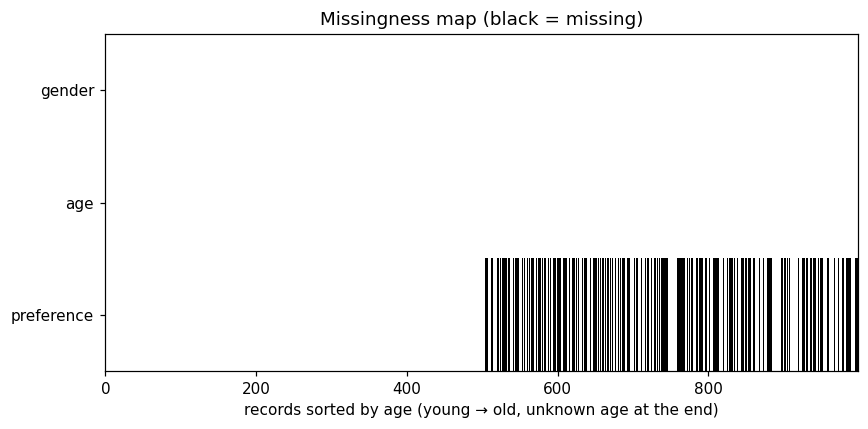

In [4]:
na = df.isna()
df["incomplete"] = na.any(axis=1)

print("Missing values per column:")
print(pd.DataFrame({"count": na.sum(), "percent": (100 * na.mean()).round(1)}))
print(f"\nRows with at least one missing value: {df['incomplete'].sum()} of {len(df)} "
      f"({100 * df['incomplete'].mean():.1f} %) -> these would be deleted")

# Missingness map: rows sorted by age so a dependency on age becomes visible
order = df.sort_values("age", na_position="last").index
fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(na.loc[order, ["gender", "age", "preference"]].T.values.astype(int),
          aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(3)); ax.set_yticklabels(["gender", "age", "preference"])
ax.set_xlabel("records sorted by age (young → old, unknown age at the end)")
ax.set_title("Missingness map (black = missing)")
ax.grid(False)
plt.tight_layout(); plt.show()

**Reading the map:** if missing values were *MCAR*, black marks would be spread evenly across all ages.
A concentration in one part of the age axis already shows that missingness is **systematic**.

## 2. Who is missing? – missingness rate by gender and by age

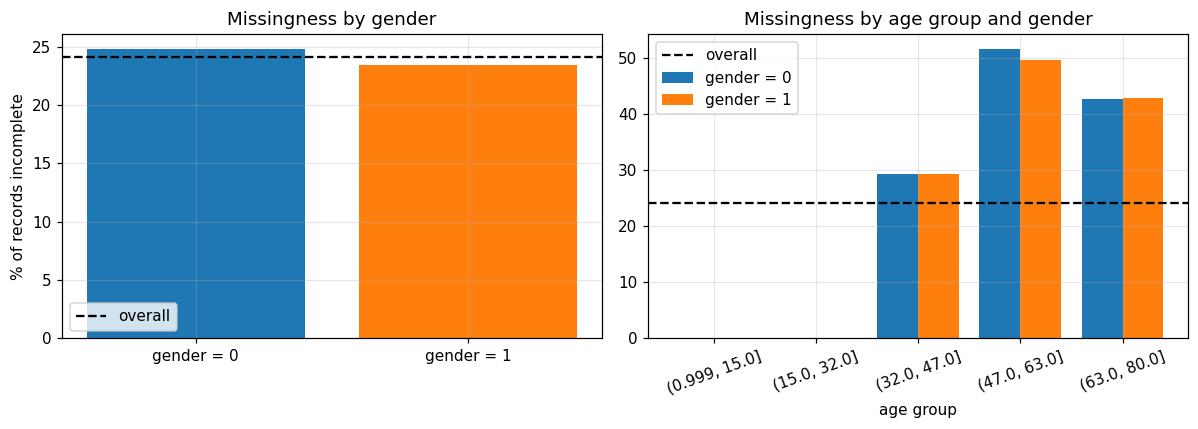

gender,0,1
age_group,,
"(0.999, 15.0]",0.0,0.0
"(15.0, 32.0]",0.0,0.0
"(32.0, 47.0]",29.2,29.2
"(47.0, 63.0]",51.6,49.5
"(63.0, 80.0]",42.6,42.9


In [5]:
known_age = df["age"].notna()
df["age_group"] = pd.qcut(df.loc[known_age, "age"], q=5, duplicates="drop")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

rate_g = df.dropna(subset=["gender"]).groupby("gender")["incomplete"].mean() * 100
axes[0].bar([f"gender = {g:g}" for g in rate_g.index], rate_g.values,
            color=[G_COLORS[g] for g in rate_g.index])
axes[0].axhline(100 * df["incomplete"].mean(), ls="--", c="k", label="overall")
axes[0].set_ylabel("% of records incomplete"); axes[0].set_title("Missingness by gender"); axes[0].legend()

rate_ag = (df.dropna(subset=["gender", "age_group"])
             .groupby(["age_group", "gender"], observed=True)["incomplete"].mean().unstack() * 100)
x = np.arange(len(rate_ag)); w = 0.4
for i, g in enumerate(rate_ag.columns):
    axes[1].bar(x + (i - 0.5) * w, rate_ag[g], w, color=G_COLORS[g], label=f"gender = {g:g}")
axes[1].axhline(100 * df["incomplete"].mean(), ls="--", c="k", label="overall")
axes[1].set_xticks(x); axes[1].set_xticklabels([str(i) for i in rate_ag.index], rotation=20)
axes[1].set_xlabel("age group"); axes[1].set_title("Missingness by age group and gender"); axes[1].legend()
plt.tight_layout(); plt.show()
rate_ag.round(1)

**Interpretation:** the share of incomplete records is not flat – it changes clearly with age (and gender).
So whether a row gets deleted depends on the respondent's characteristics → **the data are not MCAR**.

## 3. How do these groups rate the product?

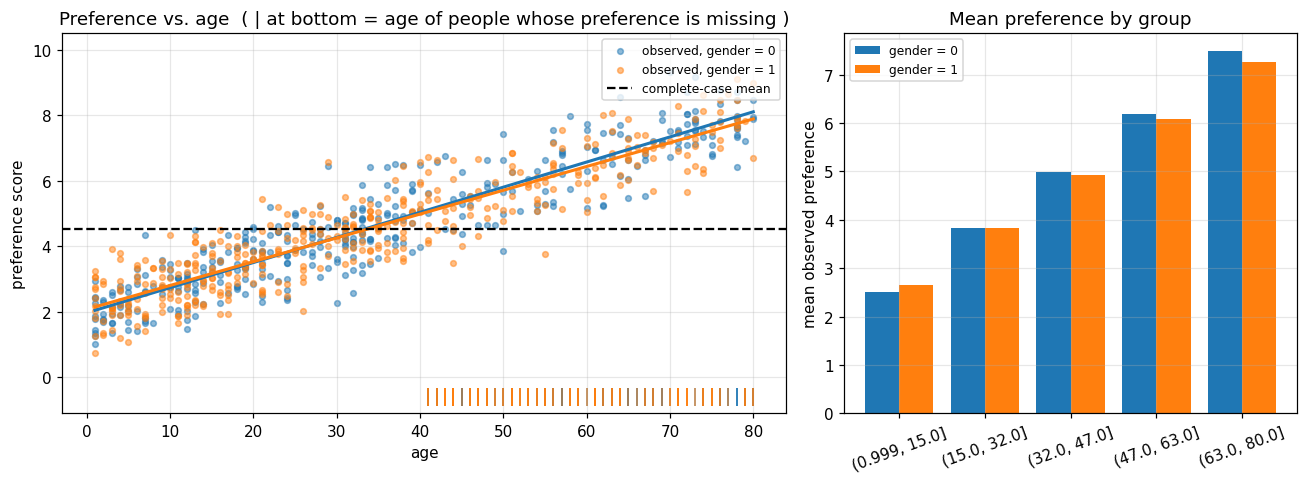

Correlation across groups between missingness rate and mean preference: r = 0.90


In [6]:
obs = df.dropna(subset=["gender", "age", "preference"])
miss_pref = df[df["preference"].isna() & df["age"].notna() & df["gender"].notna()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
for g in G_LEVELS:
    s = obs[obs["gender"] == g]
    ax.scatter(s["age"], s["preference"], s=14, alpha=0.5, color=G_COLORS[g], label=f"observed, gender = {g:g}")
    if len(s) > 2:
        b = np.polyfit(s["age"], s["preference"], 1)
        xx = np.linspace(df["age"].min(), df["age"].max(), 50)
        ax.plot(xx, np.polyval(b, xx), color=G_COLORS[g], lw=2)
    m = miss_pref[miss_pref["gender"] == g]
    ax.plot(m["age"], np.full(len(m), -0.6), "|", ms=12, color=G_COLORS[g], alpha=0.7)
ax.axhline(obs["preference"].mean(), ls="--", c="k", label="complete-case mean")
ax.set_ylim(-1.1, 10.5); ax.set_xlabel("age"); ax.set_ylabel("preference score")
ax.set_title("Preference vs. age  ( | at bottom = age of people whose preference is missing )")
ax.legend(fontsize=8, loc="upper right")

ax = axes[1]
mean_ag = obs.assign(age_group=df.loc[obs.index, "age_group"]) \
             .groupby(["age_group", "gender"], observed=True)["preference"].mean().unstack()
for i, g in enumerate(mean_ag.columns):
    ax.bar(np.arange(len(mean_ag)) + (i - 0.5) * 0.4, mean_ag[g], 0.4, color=G_COLORS[g], label=f"gender = {g:g}")
ax.set_xticks(range(len(mean_ag))); ax.set_xticklabels([str(i) for i in mean_ag.index], rotation=20)
ax.set_ylabel("mean observed preference"); ax.set_title("Mean preference by group"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# correlation between "group is often missing" and "group likes the product"
cmp = pd.concat({"% incomplete": rate_ag.stack(), "mean preference": mean_ag.stack()}, axis=1).dropna()
r = np.corrcoef(cmp["% incomplete"], cmp["mean preference"])[0, 1]
print(f"Correlation across groups between missingness rate and mean preference: r = {r:.2f}")

**Key figure.** The groups that are missing most often (bars in step 2, tick marks at the bottom of the scatter)
are the groups with **high** preference scores. The two facts together mean: the records that get deleted are
predominantly high-preference records, so the surviving complete cases are skewed towards low scores.

## 4. What does deletion do to the sample and the estimated mean?

Complete cases (rows deleted)       4.531
Post-stratified (gender × age)      4.956
Regression imputation               4.985

Under-estimation by deletion ≈ 0.43 points (8.6 %)


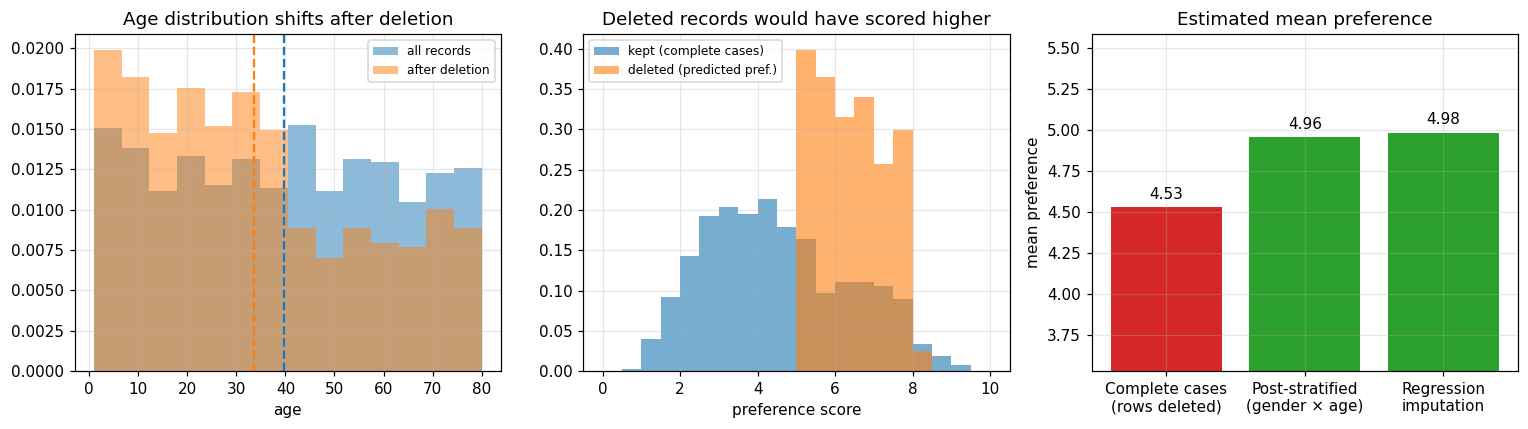

In [7]:
cc = df.dropna(subset=["gender", "age", "preference"])          # listwise deletion

# Corrected estimate: re-weight observed group means to the FULL sample composition
# (post-stratification on gender × age group, uses all records whose gender/age are known)
strata = df.dropna(subset=["gender", "age_group"])
w = strata.groupby(["gender", "age_group"], observed=True).size() / len(strata)
m = cc.assign(age_group=df.loc[cc.index, "age_group"]).groupby(["gender", "age_group"], observed=True)["preference"].mean()
common = w.index.intersection(m.index)
mean_strat = float((m[common] * w[common]).sum() / w[common].sum())

# Model-based estimate: regression pref ~ age + gender, predict missing preferences
X = np.c_[np.ones(len(cc)), cc["age"], cc["gender"]]
beta, *_ = np.linalg.lstsq(X, cc["preference"].values, rcond=None)
full = df.dropna(subset=["gender", "age"]).copy()
pred = np.clip(np.c_[np.ones(len(full)), full["age"], full["gender"]] @ beta, 0, 10)
full["pref_imp"] = full["preference"].fillna(pd.Series(pred, index=full.index))
mean_reg = full["pref_imp"].mean()

mean_cc = cc["preference"].mean()
res = pd.Series({"Complete cases\n(rows deleted)": mean_cc,
                 "Post-stratified\n(gender × age)": mean_strat,
                 "Regression\nimputation": mean_reg})
for k, v in res.items(): print(f"{k.replace(chr(10), ' '):35s} {v:.3f}")
print(f"\nUnder-estimation by deletion ≈ {mean_strat - mean_cc:.2f} points "
      f"({100 * (mean_strat - mean_cc) / mean_strat:.1f} %)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# (a) sample composition: full vs. after deletion
ag_full = df["age"].dropna(); ag_cc = cc["age"]
bins = np.linspace(ag_full.min(), ag_full.max(), 15)
axes[0].hist(ag_full, bins=bins, alpha=0.5, density=True, label="all records")
axes[0].hist(ag_cc, bins=bins, alpha=0.5, density=True, label="after deletion")
axes[0].axvline(ag_full.mean(), c="tab:blue", ls="--"); axes[0].axvline(ag_cc.mean(), c="tab:orange", ls="--")
axes[0].set_xlabel("age"); axes[0].set_title("Age distribution shifts after deletion"); axes[0].legend(fontsize=8)

# (b) preference distribution: observed vs. imputed for the deleted ones
b2 = np.linspace(0, 10, 21)
axes[1].hist(cc["preference"], bins=b2, alpha=0.6, density=True, label="kept (complete cases)")
axes[1].hist(full.loc[full["preference"].isna(), "pref_imp"], bins=b2, alpha=0.6, density=True,
             label="deleted (predicted pref.)")
axes[1].set_xlabel("preference score"); axes[1].set_title("Deleted records would have scored higher")
axes[1].legend(fontsize=8)

# (c) the estimates
cols = ["tab:red", "tab:green", "tab:green"]
axes[2].bar(res.index, res.values, color=cols)
for i, v in enumerate(res.values):
    axes[2].text(i, v + 0.05, f"{v:.2f}", ha="center")
axes[2].set_ylim(min(res) - 1, max(res) + 0.6); axes[2].set_ylabel("mean preference")
axes[2].set_title("Estimated mean preference")
plt.tight_layout(); plt.show()

* Left: after deletion the sample over-represents the groups that answer reliably → it no longer matches the population.
* Middle: the records removed by deletion belong to high-preference groups.
* Right: the complete-case mean is **lower** than estimates that account for who is missing → **underestimation**.

(The corrected estimates assume missingness depends only on age and gender – i.e. MAR. If people with high scores
themselves skip the question (MNAR), the true bias is even larger; deletion cannot fix either case.)

## 5. General illustration: MCAR vs. non-random missingness
Simulated population with the same structure, 1000 repetitions, 40 % of records deleted each time.

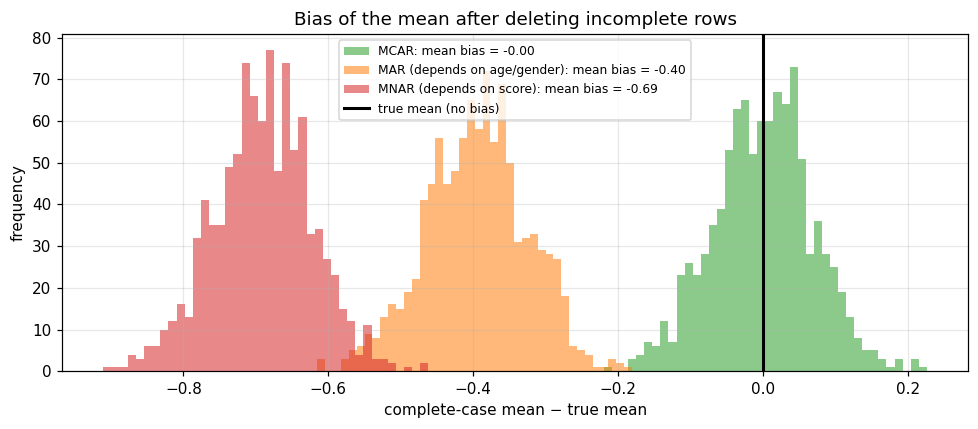

In [8]:
def simulate(mech, n=400, reps=1000, frac=0.4):
    out = []
    for _ in range(reps):
        a = rng.uniform(18, 75, n); g = rng.integers(0, 2, n)
        s = np.clip(9 - 0.08 * (a - 18) + 0.8 * g + rng.normal(0, 1, n), 0, 10)
        if mech == "MCAR":
            p = np.full(n, frac)
        elif mech == "MAR (depends on age/gender)":
            z = 2.5 - 0.08 * (a - 18) + 0.6 * g
            p = 1 / (1 + np.exp(-z)); p *= frac / p.mean()
        else:  # MNAR: depends on the score itself
            z = (s - s.mean()) * 1.2
            p = 1 / (1 + np.exp(-z)); p *= frac / p.mean()
        keep = rng.random(n) >= np.clip(p, 0, 1)
        out.append(s[keep].mean() - s.mean())
    return np.array(out)

mechs = ["MCAR", "MAR (depends on age/gender)", "MNAR (depends on score)"]
sims = {m: simulate(m) for m in mechs}

fig, ax = plt.subplots(figsize=(9, 4))
for m, c in zip(mechs, ["tab:green", "tab:orange", "tab:red"]):
    ax.hist(sims[m], bins=40, alpha=0.55, color=c, label=f"{m}: mean bias = {sims[m].mean():+.2f}")
ax.axvline(0, c="k", lw=2, label="true mean (no bias)")
ax.set_xlabel("complete-case mean − true mean"); ax.set_ylabel("frequency")
ax.set_title("Bias of the mean after deleting incomplete rows")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

* **MCAR:** deletion only reduces *n* – the estimate stays centred on the true value (unbiased, just noisier).
* **Non-random (MAR / MNAR):** when high-preference respondents are the ones who tend to be missing,
  the whole distribution of estimates moves **left of zero** → systematic **underestimation**, which more data does not fix.

## Conclusion – answer to (a)

In [9]:
print(f"""Records with missing values : {df['incomplete'].sum()} of {len(df)} ({100*df['incomplete'].mean():.1f} %)
Complete-case mean          : {mean_cc:.2f}
Post-stratified mean        : {mean_strat:.2f}
Regression-imputed mean     : {mean_reg:.2f}
Bias from deletion          : {mean_cc - mean_strat:+.2f} points""")

Records with missing values : 241 of 999 (24.1 %)
Complete-case mean          : 4.53
Post-stratified mean        : 4.96
Regression-imputed mean     : 4.98
Bias from deletion          : -0.43 points


**No – rows with missing data must not simply be removed.**

The missingness in `dataIsRemovalAllowed` is **not random**: the probability that a record is incomplete depends
on age and gender (step 2), and exactly those groups give **higher** preference scores (step 3).
Listwise deletion therefore throws away a disproportionate number of high scores, the remaining sample is
shifted towards low-preference respondents (step 4), and the mean preference is **systematically
underestimated**. The simulation (step 5) shows this is a bias, not just noise: it only vanishes under MCAR.

Better options: weight the observed data to the full sample composition (post-stratification / inverse-probability
weighting) or impute missing values using the related variables (regression or multiple imputation).